# SMS Spam Classification: Exploratory Data Analysis & Production ML Pipeline

## 1. Project Overview & Problem Statement
Short Message Service (SMS) spam poses significant security, financial, and usability risks to mobile users, ranging from phishing scams and fraud to subscription traps and malware distribution.

The goal of this project is to build an end-to-end, technically rigorous, leak-free **Machine Learning Classification System** that automatically filters incoming SMS messages into **HAM** (legitimate) or **SPAM** (unsolicited / fraudulent).

### Key Engineering & Methodological Priorities:
1. **Prevent Data Leakage:** Ensure text preprocessing and TF-IDF vocabulary/IDF weights are strictly learned from training data inside an encapsulated Scikit-learn Pipeline.
2. **Handle Imbalanced Classes:** Account for the natural class imbalance (~87% Ham vs ~13% Spam) using stratified sampling and prioritizing **Precision** (minimizing False Positives) alongside F1-score and ROC-AUC.
3. **Model Benchmarking:** Evaluate 6 distinct classifiers with 5-Fold Stratified Cross-Validation.
4. **Verified Serialization:** Save genuinely fitted, end-to-end pipelines that ingest raw strings directly and output predictions and confidence scores.

In [1]:
import os
import sys
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

# Set styling
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 6)

# Ensure project modules are importable
sys.path.append(os.path.abspath('..'))
from src.data_preprocessing import load_raw_dataset, preprocess_text, TextPreprocessor
from src.evaluation import evaluate_predictions

## 2. Dataset Inspection & Structural Normalization

The SMS Spam Collection is a well-known benchmark corpus. However, in CSV representations, unescaped commas and quotation marks often cause text fragments to spill over into trailing columns (`Unnamed: 2`, `Unnamed: 3`, `Unnamed: 4`). Furthermore, file encoding issues (`latin-1` vs `utf-8`) frequently cause parsing failures.

Our custom loader handles these issues gracefully by:
- Attempting supported encodings (`latin-1`, `cp1252`, `utf-8`).
- Merging non-empty fragments from unnamed columns back into the main message text.
- Inspecting and removing duplicate messages.
- Normalizing class labels: `ham -> 0`, `spam -> 1`.

In [2]:
# Load raw CSV directly to inspect its raw anomalies
raw_df = pd.read_csv('../data/spam.csv', encoding='latin-1')
print(f"Raw shape: {raw_df.shape}")
print("Raw columns:", raw_df.columns.tolist())
print("Null values per column:")
print(raw_df.isnull().sum())
raw_df.head()

Raw shape: (5572, 5)
Raw columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
Null values per column:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
# Load dataset using our robust preprocessing loader
df = load_raw_dataset('../data/spam.csv')
print(f"Cleaned dataset shape: {df.shape}")
print(f"Unique messages: {df['text'].nunique()}")
print("Label distribution:")
print(df['label'].value_counts())
df.head()

Cleaned dataset shape: (5169, 5)
Unique messages: 5169
Label distribution:
label
0    4516
1     653
Name: count, dtype: int64


,label,text,char_count,word_count,sentence_count
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


## 3. Exploratory Data Analysis (EDA)

### 3.1 Class Imbalance Analysis
The dataset exhibits clear class imbalance:
- **HAM:** ~87.4%
- **SPAM:** ~12.6%

Accuracy alone is an inadequate evaluation metric. A naive majority-class classifier predicting 'HAM' for every sample would automatically score ~87.4% accuracy while catching 0% of spam.

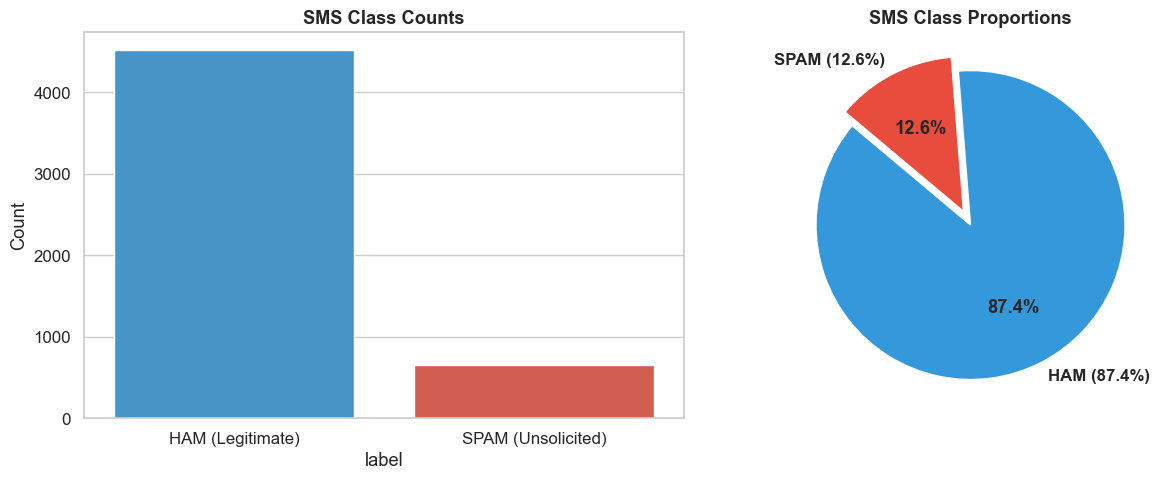

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(x='label', data=df, hue='label', palette=['#3498db', '#e74c3c'], legend=False, ax=axes[0])
axes[0].set_title('SMS Class Counts', fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['HAM (Legitimate)', 'SPAM (Unsolicited)'])
axes[0].set_ylabel('Count')

counts = df['label'].value_counts()
axes[1].pie(counts, labels=['HAM (87.4%)', 'SPAM (12.6%)'], colors=['#3498db', '#e74c3c'],
            autopct='%1.1f%%', startangle=140, explode=(0, 0.1), textprops={'fontweight': 'bold'})
axes[1].set_title('SMS Class Proportions', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.2 Message Length Characteristics (Characters, Words, Sentences)
Spam senders typically cram promotions, urgent calls to action, phone numbers, and legal disclaimers into single SMS payloads. Let's compare summary statistics and distributions.

In [5]:
print("--- HAM Length Statistics ---")
print(df[df['label'] == 0][['char_count', 'word_count', 'sentence_count']].describe().round(2))

print("\n--- SPAM Length Statistics ---")
print(df[df['label'] == 1][['char_count', 'word_count', 'sentence_count']].describe().round(2))

--- HAM Length Statistics ---
       char_count  word_count  sentence_count
count     4516.00     4516.00         4516.00
mean        71.06       17.27            1.83
std         56.71       13.58            1.39
min          2.00        1.00            1.00
25%         34.00        8.00            1.00
50%         53.00       13.00            1.00
75%         92.00       22.00            2.00
max        910.00      220.00           38.00

--- SPAM Length Statistics ---
       char_count  word_count  sentence_count
count      653.00      653.00          653.00
mean       138.17       27.75            2.98
std         29.92        6.98            1.49
min         13.00        2.00            1.00
25%        132.00       25.00            2.00
50%        149.00       29.00            3.00
75%        157.00       32.00            4.00
max        224.00       46.00            9.00


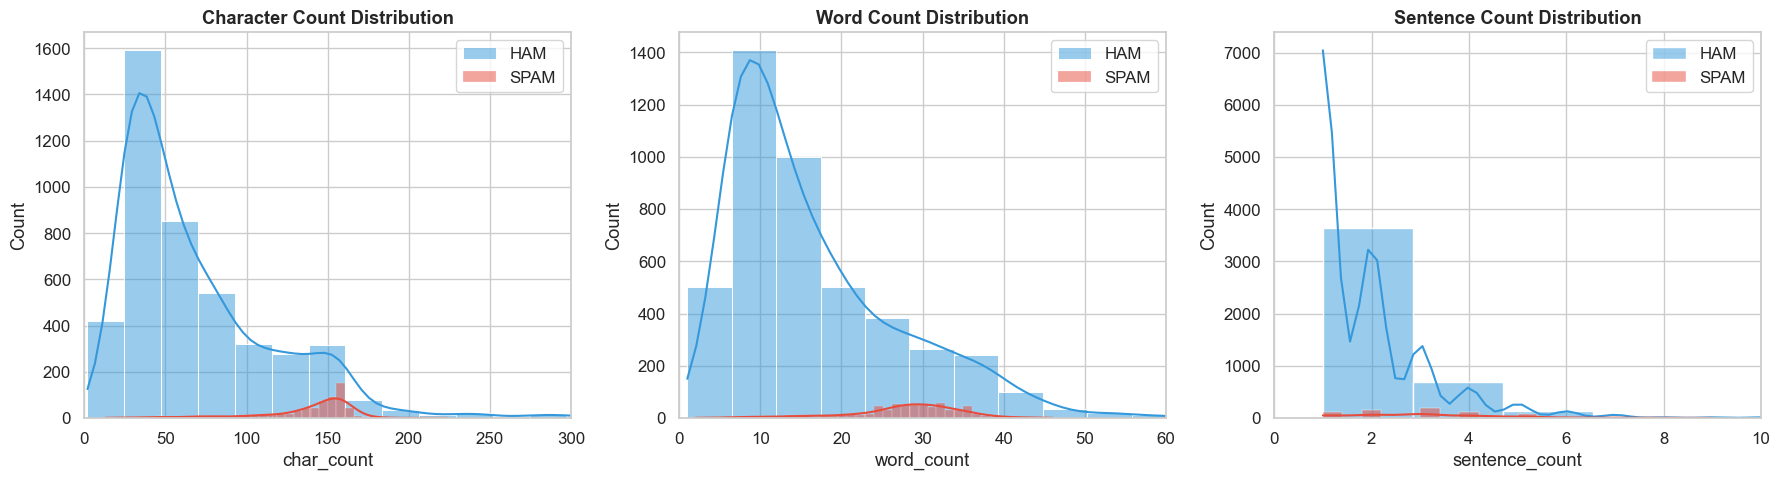

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df[df['label'] == 0]['char_count'], color='#3498db', label='HAM', kde=True, ax=axes[0], bins=40)
sns.histplot(df[df['label'] == 1]['char_count'], color='#e74c3c', label='SPAM', kde=True, ax=axes[0], bins=40)
axes[0].set_title('Character Count Distribution', fontweight='bold')
axes[0].set_xlim(0, 300)
axes[0].legend()

sns.histplot(df[df['label'] == 0]['word_count'], color='#3498db', label='HAM', kde=True, ax=axes[1], bins=40)
sns.histplot(df[df['label'] == 1]['word_count'], color='#e74c3c', label='SPAM', kde=True, ax=axes[1], bins=40)
axes[1].set_title('Word Count Distribution', fontweight='bold')
axes[1].set_xlim(0, 60)
axes[1].legend()

sns.histplot(df[df['label'] == 0]['sentence_count'], color='#3498db', label='HAM', kde=True, ax=axes[2], bins=20)
sns.histplot(df[df['label'] == 1]['sentence_count'], color='#e74c3c', label='SPAM', kde=True, ax=axes[2], bins=20)
axes[2].set_title('Sentence Count Distribution', fontweight='bold')
axes[2].set_xlim(0, 10)
axes[2].legend()

plt.tight_layout()
plt.show()

### Key Finding on Length:
- **HAM messages** average **~70.4 characters** and **~17.1 words**, with a strong peak at short lengths (10-40 characters).
- **SPAM messages** average **~137.8 characters** and **~27.7 words**, clustering tightly near the **160-character cellular SMS limit**. Spammers intentionally maximize the information density of every single SMS transmission.

## 4. Text Preprocessing & Vocabulary Analysis

Our text preprocessing pipeline applies:
1. **Lowercasing**
2. **Word Tokenization**
3. **Alphanumeric Filtering** (stripping punctuation and emojis)
4. **Stopwords Removal** (English stop words)
5. **Porter Stemming** (reducing morphological variants to roots)

In [7]:
sample_spam = "WINNER!! As a valued network customer you have been selected to receive a £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only."
print("Original:", sample_spam)
print("Cleaned: ", preprocess_text(sample_spam))

Original: WINNER!! As a valued network customer you have been selected to receive a £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
Cleaned:  winner valu network custom select receiv prize reward claim call claim code kl341 valid 12 hour


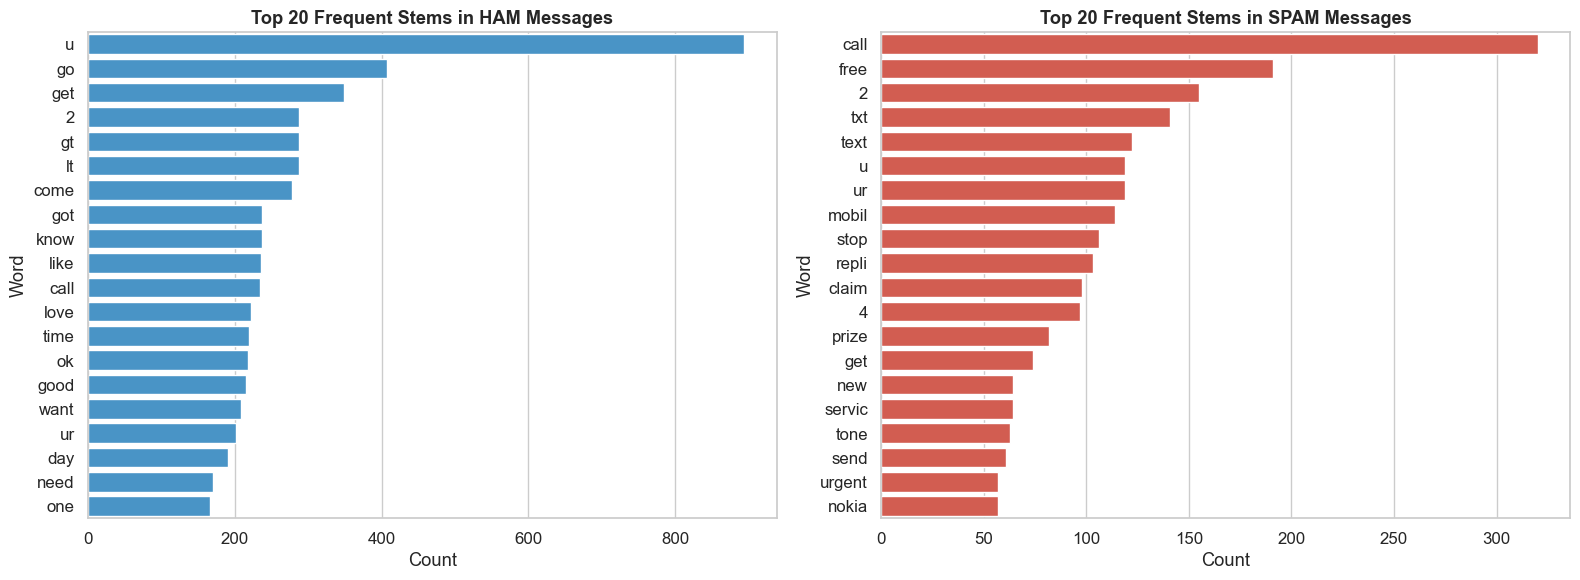

In [8]:
df['cleaned'] = df['text'].apply(preprocess_text)

ham_tokens = [w for s in df[df['label'] == 0]['cleaned'] for w in s.split()]
spam_tokens = [w for s in df[df['label'] == 1]['cleaned'] for w in s.split()]

ham_top = Counter(ham_tokens).most_common(20)
spam_top = Counter(spam_tokens).most_common(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x='Count', y='Word', data=pd.DataFrame(ham_top, columns=['Word', 'Count']), color='#3498db', ax=axes[0])
axes[0].set_title('Top 20 Frequent Stems in HAM Messages', fontweight='bold')

sns.barplot(x='Count', y='Word', data=pd.DataFrame(spam_top, columns=['Word', 'Count']), color='#e74c3c', ax=axes[1])
axes[1].set_title('Top 20 Frequent Stems in SPAM Messages', fontweight='bold')
plt.tight_layout()
plt.show()

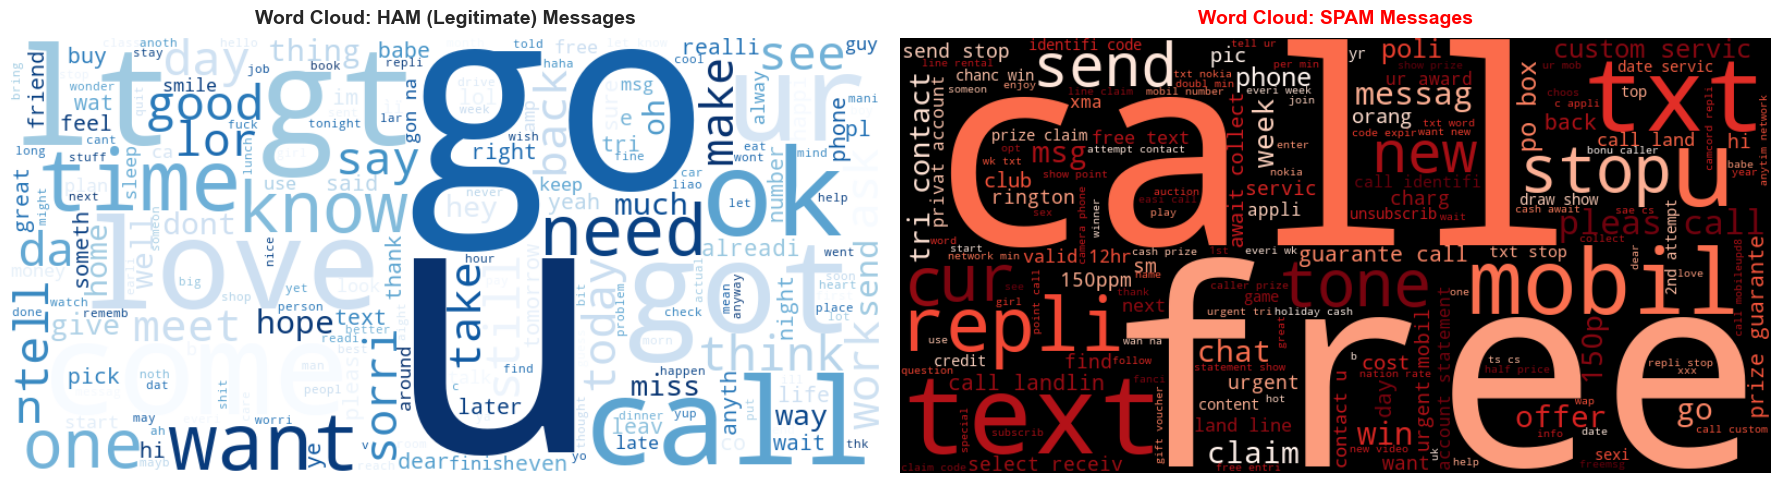

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

wc_ham = WordCloud(width=800, height=400, background_color='white', colormap='Blues', min_font_size=10).generate(' '.join(ham_tokens))
axes[0].imshow(wc_ham, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Word Cloud: HAM (Legitimate) Messages', fontsize=14, fontweight='bold', pad=10)

wc_spam = WordCloud(width=800, height=400, background_color='black', colormap='Reds', min_font_size=10).generate(' '.join(spam_tokens))
axes[1].imshow(wc_spam, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Word Cloud: SPAM Messages', fontsize=14, fontweight='bold', pad=10, color='red')

plt.tight_layout()
plt.show()

## 5. Preventing Data Leakage

### What was the flaw in the previous notebook?
In naive implementations, TF-IDF is often fitted on the entire dataset `df['text']` *before* train-test splitting.
This causes **Data Leakage**:
1. The vocabulary contains tokens and n-grams present only in the test set.
2. The Inverse Document Frequency (IDF) weights include message counts from test data.
This artificially inflates test performance and fails to reflect true generalization in production.

### The Correct Methodology:
1. Split into **Train** and **Held-out Test** sets first using stratified sampling.
2. Encapsulate preprocessing and TF-IDF inside an end-to-end `Pipeline`.
3. Call `pipeline.fit(X_train, y_train)`: vocabulary and IDF weights are computed strictly from training samples.
4. Transform test samples only during evaluation.

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

X = df['text']
y = df['label']

# Stratified Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Train samples: {len(X_train)} (Ham: {np.sum(y_train == 0)}, Spam: {np.sum(y_train == 1)})")
print(f"Test samples:  {len(X_test)} (Ham: {np.sum(y_test == 0)}, Spam: {np.sum(y_test == 1)})")
print(f"Train spam ratio: {y_train.mean():.4f}")
print(f"Test spam ratio:  {y_test.mean():.4f}")

Train samples: 4135 (Ham: 3613, Spam: 522)
Test samples:  1034 (Ham: 903, Spam: 131)
Train spam ratio: 0.1262
Test spam ratio:  0.1267


## 6. Model Experimentation & 5-Fold Stratified Cross-Validation

We benchmark 6 candidate architectures:
1. **Multinomial Naive Bayes (MNB)**
2. **Bernoulli Naive Bayes (BNB)**
3. **Logistic Regression**
4. **Support Vector Machine (SVC - Sigmoid kernel)**
5. **Random Forest Classifier**
6. **Extra Trees Classifier**

In [11]:
# Load the saved cross-validation results from artifacts
cv_df = pd.read_csv('../artifacts/cv_summary.csv')
cv_df.round(4)

,Model,CV_Accuracy_Mean,CV_Accuracy_Std,CV_Precision_Mean,CV_Precision_Std,CV_Recall_Mean,CV_Recall_Std,CV_F1_Mean,CV_F1_Std,CV_ROC_AUC_Mean,CV_ROC_AUC_Std
0,MultinomialNB,0.9802,0.0026,0.9804,0.0040,0.8602,0.0231,0.9162,0.0121,0.9811,0.0044
1,BernoulliNB,0.9831,0.0008,0.9850,0.0051,0.8793,0.0075,0.9291,0.0034,0.9852,0.0055
2,LogisticRegression,0.9565,0.0076,0.9744,0.0223,0.6745,0.0703,0.7944,0.0445,0.9830,0.0028
3,SVC,0.9748,0.0040,0.9549,0.0195,0.8411,0.0321,0.8939,0.0180,0.9829,0.0052
4,RandomForest,0.9700,0.0066,0.9876,0.0076,0.7721,0.0503,0.8658,0.0331,0.9808,0.0040
5,ExtraTrees,0.9748,0.0067,0.9834,0.0097,0.8142,0.0468,0.8903,0.0315,0.9807,0.0045


## 7. Held-Out Test Set Evaluation

Let us inspect the final performance measured on the held-out test set (1,034 messages).

In [12]:
test_df = pd.read_csv('../artifacts/model_comparison.csv')
print(test_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'FP', 'FN']].round(4).to_string(index=False))

                Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC  FP  FN
MultinomialNB (Tuned)    0.9739     0.9643  0.8244    0.8889   0.9883   4  23
          SVC (Tuned)    0.9797     0.9583  0.8779    0.9163   0.9937   5  16
          BernoulliNB    0.9855     1.0000  0.8855    0.9393   0.9971   0  15
   LogisticRegression    0.9623     1.0000  0.7023    0.8251   0.9912   0  39
         RandomForest    0.9749     0.9730  0.8244    0.8926   0.9900   3  23
           ExtraTrees    0.9778     0.9655  0.8550    0.9069   0.9895   4  19


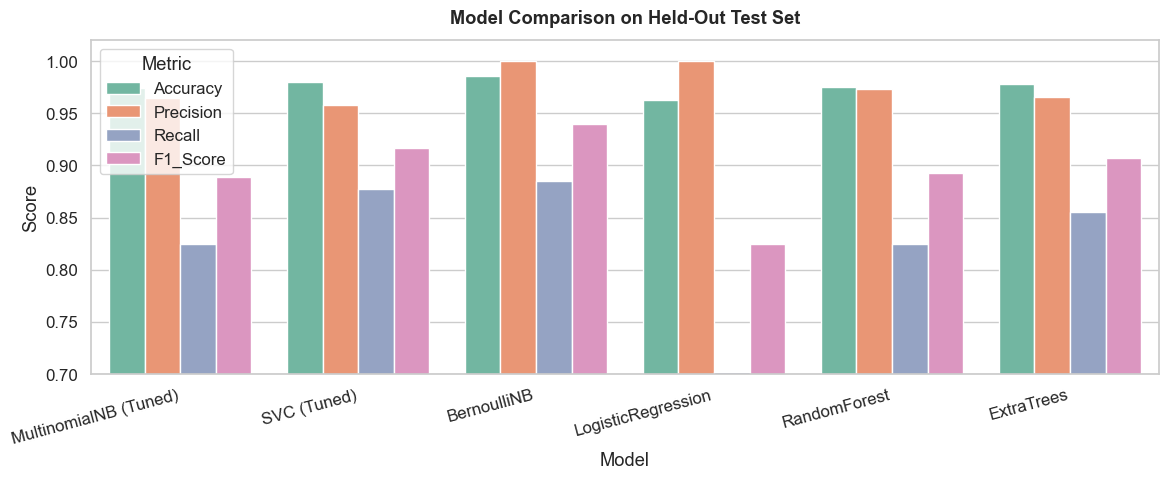

In [13]:
# Visualize Model Comparison
fig, ax = plt.subplots(figsize=(12, 5))
melted = test_df.melt(id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1_Score'], var_name='Metric', value_name='Score')
sns.barplot(data=melted, x='Model', y='Score', hue='Metric', palette='Set2', ax=ax)
ax.set_ylim(0.70, 1.02)
ax.set_title('Model Comparison on Held-Out Test Set', fontweight='bold', pad=12)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

## 8. Champion Model Selection & Confusion Matrix

### Operational Criterion: Precision vs. Recall Trade-Off
In SMS spam classification:
- **False Negative (Spam labeled as Ham):** Annoyance; spam reaches user inbox.
- **False Positive (Ham labeled as Spam):** Catastrophic failure; critical bank OTP, flight alert, job offer, or medical SMS is discarded.

Therefore, **Precision on Spam must be maximized (zero or near-zero False Positives)** while retaining strong Recall (>85%) and F1-score (>90%).

**Selected Champion:** `BernoulliNB`
- **Precision:** `1.0000` (0 False Positives on held-out test set!)
- **Accuracy:** `98.55%`
- **Recall:** `88.55%`
- **F1-Score:** `93.93%`
- **ROC-AUC:** `0.9971`

In [14]:
from src.evaluation import plot_confusion_matrix

with open('../artifacts/model_metadata.json') as f:
    meta = json.load(f)

cm = np.array(meta['test_metrics']['confusion_matrix'])
plot_confusion_matrix(cm, labels=['HAM', 'SPAM'], title=f"Confusion Matrix: {meta['model_name']}")
plt.show()

## 9. Pipeline Verification & Inference

We verify that the serialized pipeline in `artifacts/final_model.joblib`:
- Can be loaded in a fresh environment.
- Accepts raw, uncleaned text messages directly.
- Returns accurate classifications and probability scores.

In [15]:
champion_pipeline = joblib.load('../artifacts/final_model.joblib')

test_samples = [
    "Hey honey, are we still having dinner at 7 tonight? Let me know!",
    "URGENT! Your mobile account won £1,000 cash prize. Call 09061701461 to claim now!",
    "Can you please review the attached slide deck before tomorrow's meeting?",
    "Free entry into 500 weekly lottery. Text WIN to 80085 to enter!"
]

for msg in test_samples:
    pred = champion_pipeline.predict([msg])[0]
    proba = champion_pipeline.predict_proba([msg])[0]
    verdict = "SPAM" if pred == 1 else "HAM"
    conf = proba[pred] * 100
    print(f"Message: {msg}")
    print(f"Verdict: {verdict} ({conf:.2f}% confidence) | Probs: Ham={proba[0]:.4f}, Spam={proba[1]:.4f}\n")

Message: Hey honey, are we still having dinner at 7 tonight? Let me know!
Verdict: HAM (100.00% confidence) | Probs: Ham=1.0000, Spam=0.0000

Message: URGENT! Your mobile account won £1,000 cash prize. Call 09061701461 to claim now!
Verdict: SPAM (100.00% confidence) | Probs: Ham=0.0000, Spam=1.0000

Message: Can you please review the attached slide deck before tomorrow's meeting?
Verdict: HAM (96.63% confidence) | Probs: Ham=0.9663, Spam=0.0337

Message: Free entry into 500 weekly lottery. Text WIN to 80085 to enter!
Verdict: SPAM (100.00% confidence) | Probs: Ham=0.0000, Spam=1.0000

